# 02 · ACO feature selection + Decision Tree

**Task:** predict tomorrow's AQI for a city from data known at the end of today.

**Split by time** (no shuffling, so no future data leaks into training):
- train: 2018-01-01 → 2022-12-31
- validation: 2023 (used by ACO to score feature subsets)
- test: 2024 (touched once, for the final numbers)

**Baselines:** persistence (tomorrow = today), Decision Tree on all features, Random Forest on all features.

In [1]:
import sys, os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, BaggingRegressor

sys.path.insert(0, os.path.abspath("../src"))
from aco_optimizer import ACO_FeatureSelection, feature_category

sns.set_theme(style="whitegrid")
os.makedirs("../results/models", exist_ok=True)
os.makedirs("../results/plots", exist_ok=True)
os.makedirs("../results/reports", exist_ok=True)

In [2]:
df = pd.read_csv("../data/processed/aqi_daily_features.csv", parse_dates=["date"])
TARGET = "target_AQI_next_day"
exclude = {"city", "date", "prominent_pollutant", "n_stations", TARGET}
features = [c for c in df.columns if c not in exclude and pd.api.types.is_numeric_dtype(df[c])]

train = df[df["date"] < "2023-01-01"]
val = df[(df["date"] >= "2023-01-01") & (df["date"] < "2024-01-01")]
test = df[df["date"] >= "2024-01-01"]
print(f"{len(features)} features | train {len(train)} | val {len(val)} | test {len(test)}")

medians = train[features].median()          # imputation fitted on training data only
prep = lambda d: d[features].fillna(medians)
X_tr, y_tr = prep(train), train[TARGET]
X_va, y_va = prep(val), val[TARGET]
X_te, y_te = prep(test), test[TARGET]
X_trva, y_trva = pd.concat([X_tr, X_va]), pd.concat([y_tr, y_va])

pd.Series([feature_category(f) for f in features]).value_counts()

91 features | train 10619 | val 2190 | test 2190


policy     67
other      18
weather     6
Name: count, dtype: int64

## Run ACO

In [3]:
aco = ACO_FeatureSelection(
    n_ants=30, n_iterations=60, alpha=1.0, beta=2.0, rho=0.1, q0=0.5,
    policy_weight=1.5, size_penalty=0.05, policy_bonus=0.03, weather_penalty=0.03,
    min_features=4, max_features=15, patience=15, random_state=42,
)
res = aco.optimize(X_tr, y_tr, X_va, y_va)
best = res["best_features"]
print(f"{len(best)} of {len(features)} features selected after {res['total_iterations']} iterations "
      f"({res['n_evaluations']} subsets evaluated), val RMSE {res['val_rmse']:.2f}")
pd.DataFrame({"feature": best, "category": [feature_category(f) for f in best]})

12 of 91 features selected after 39 iterations (1072 subsets evaluated), val RMSE 29.62


,feature,category
0,PM10_lag2,policy
1,PM10,policy
2,NO2_avg7,policy
3,AQI_lag2,other
4,PM2.5_avg3,policy
5,PM2.5,policy
6,PM2.5_avg7,policy
7,PM10_avg3,policy
8,PM10_avg7,policy
9,PM2.5_lag1,policy


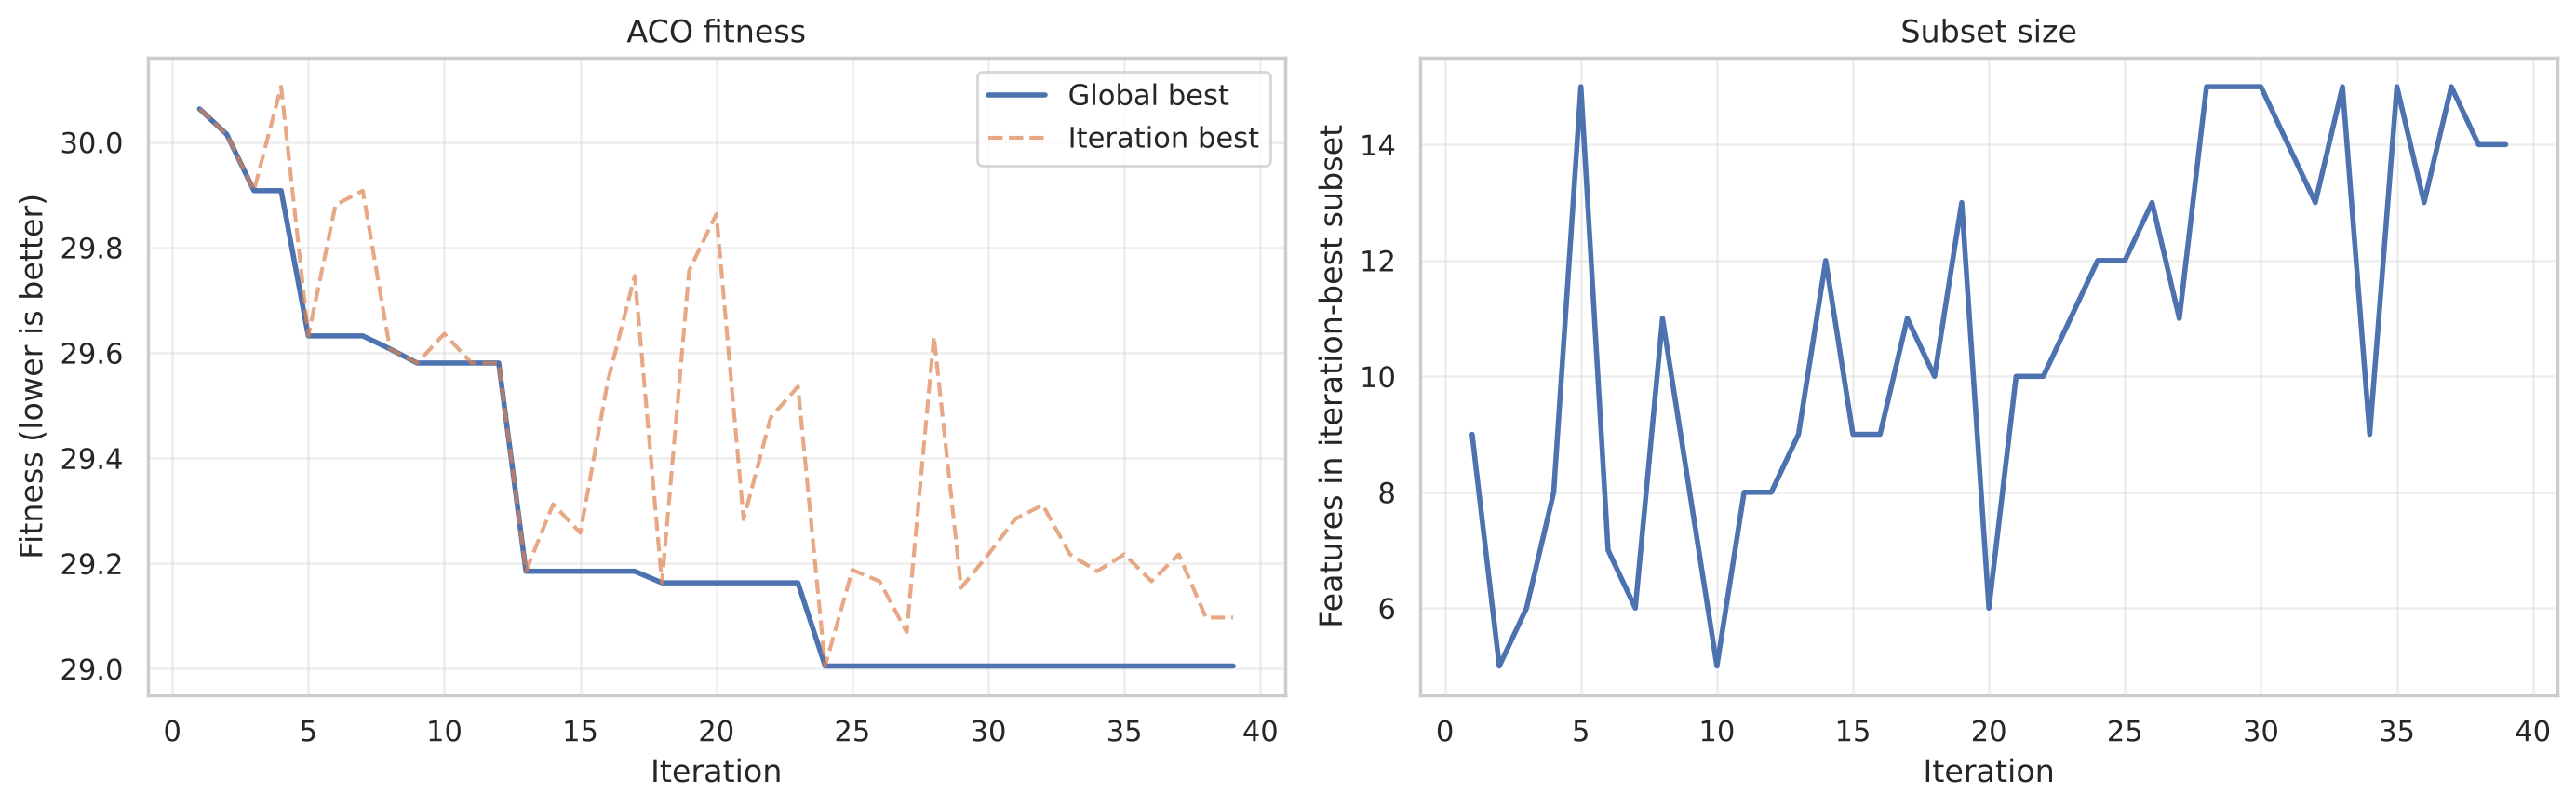

In [4]:
aco.plot_convergence("../results/plots/aco_convergence.png");

## Final models
Refit on train + validation, evaluate once on 2024.

In [5]:
tree_kw = dict(max_depth=10, min_samples_split=20, min_samples_leaf=10, random_state=42)
models = {
    "ACO + Decision Tree": (DecisionTreeRegressor(**tree_kw), best),
    "ACO + Bagged Trees": (BaggingRegressor(DecisionTreeRegressor(**tree_kw), n_estimators=50,
                                            random_state=42, n_jobs=-1), best),
    "Decision Tree (all features)": (DecisionTreeRegressor(**tree_kw), features),
    "Random Forest (all features)": (RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                                           random_state=42, n_jobs=-1), features),
}
rows, preds = [], {}
for name, (m, cols) in models.items():
    m.fit(X_trva[cols], y_trva)
    preds[name] = m.predict(X_te[cols])
    rows.append({"model": name, "n_features": len(cols), **ACO_FeatureSelection.evaluate_model(y_te, preds[name])})

preds["Persistence (today's AQI)"] = test["AQI"].values
rows.append({"model": "Persistence (today's AQI)", "n_features": 1,
             **ACO_FeatureSelection.evaluate_model(y_te, test["AQI"].values)})
results = pd.DataFrame(rows).set_index("model").round(3)
results

,n_features,rmse,mae,r2
model,,,,
ACO + Decision Tree,12,28.023,16.473,0.867
ACO + Bagged Trees,12,25.166,14.889,0.893
Decision Tree (all features),91,27.920,16.603,0.868
Random Forest (all features),91,23.943,14.403,0.903
Persistence (today's AQI),1,26.713,14.899,0.879


## Error by city

In [6]:
by_city = pd.DataFrame({
    name: pd.Series(np.abs(p - y_te.values), index=test["city"].values).groupby(level=0).mean()
    for name, p in preds.items()
}).round(1)
by_city

,ACO + Decision Tree,ACO + Bagged Trees,Decision Tree (all features),Random Forest (all features),Persistence (today's AQI)
Bengaluru,9.9,9.1,10.1,8.9,9.4
Chennai,13.0,12.3,12.1,10.7,11.1
Delhi,35.0,30.8,34.9,29.5,31.5
Hyderabad,9.6,8.9,9.6,8.8,9.3
Kolkata,18.7,17.0,19.0,16.3,17.2
Mumbai,12.5,11.3,14.0,12.2,10.9


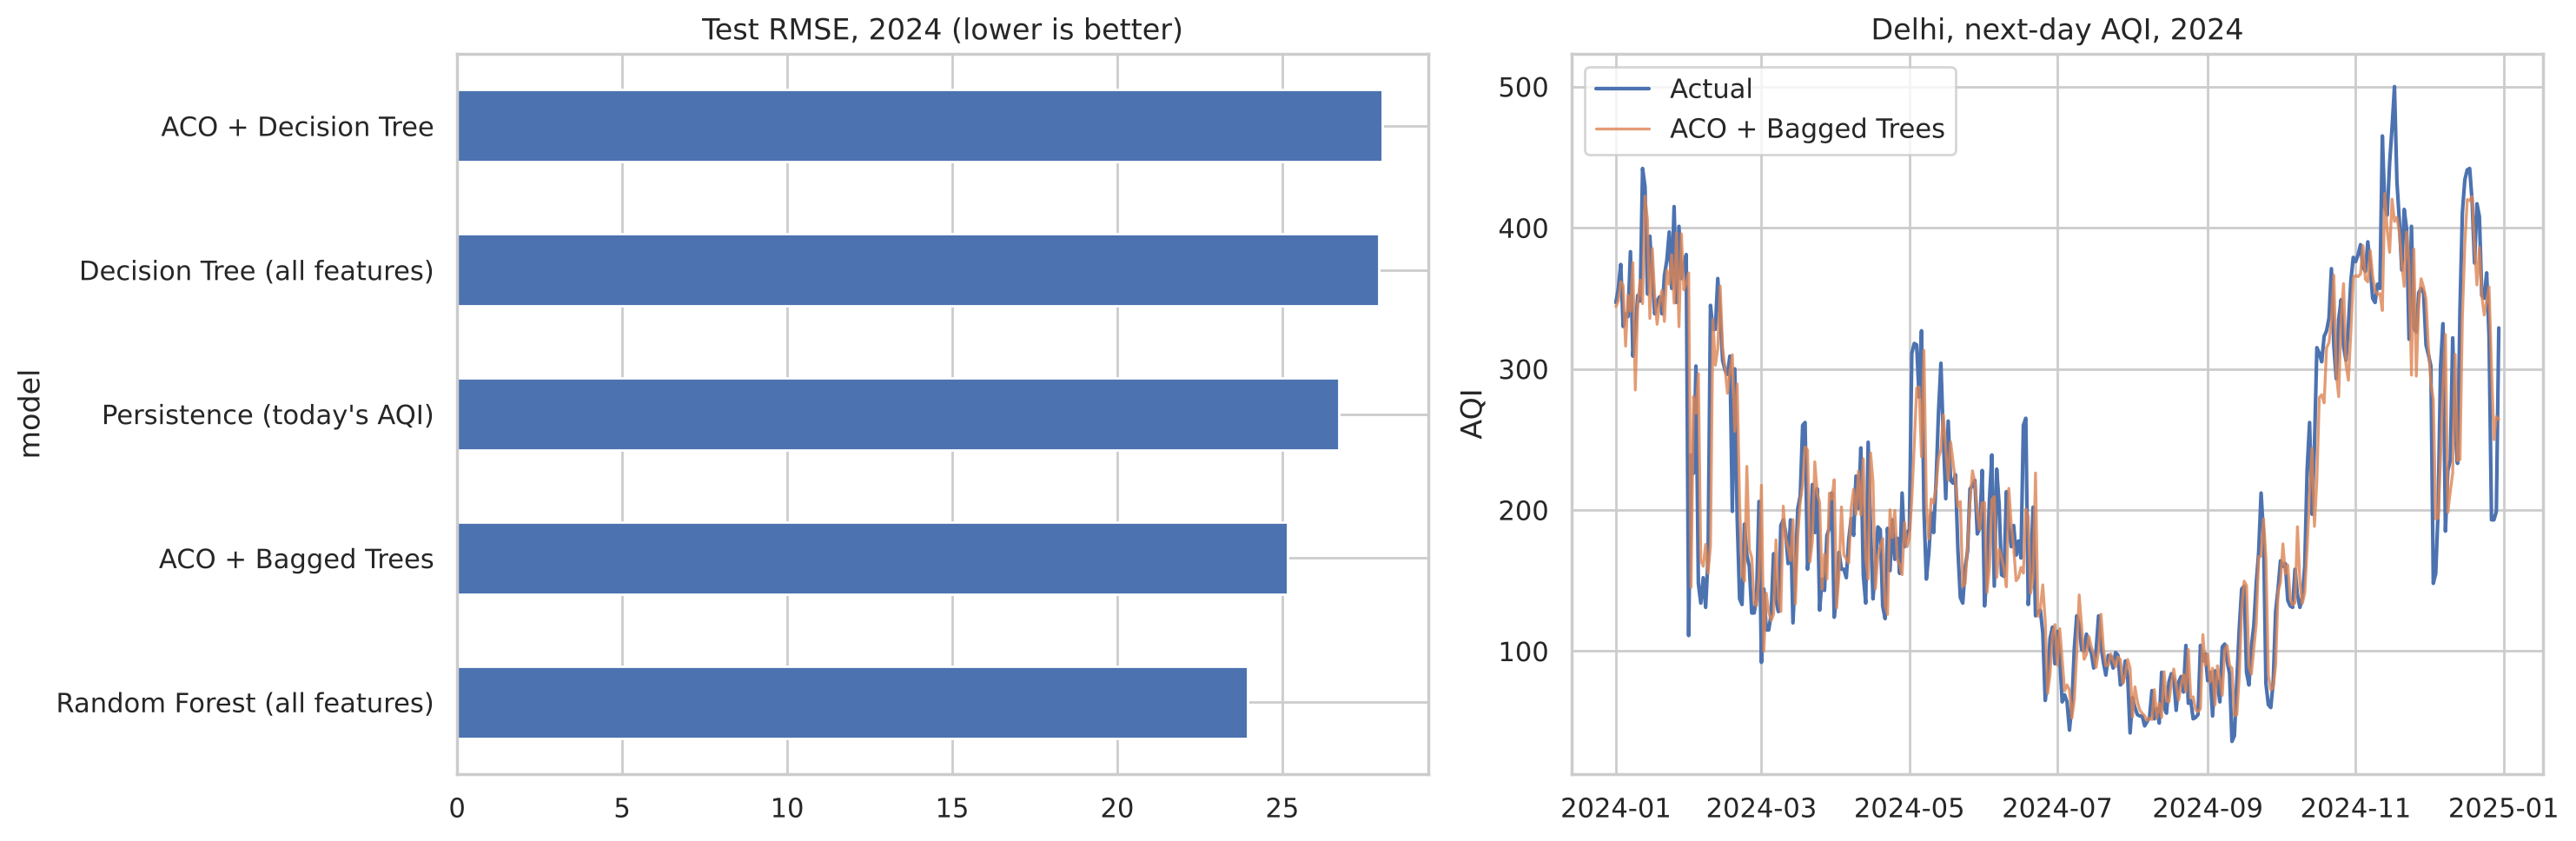

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
results["rmse"].sort_values().plot.barh(ax=axes[0], title="Test RMSE, 2024 (lower is better)")
d = test.assign(pred=preds["ACO + Bagged Trees"])
d = d[d["city"] == "Delhi"]
axes[1].plot(d["date"], d[TARGET], label="Actual", lw=1.5)
axes[1].plot(d["date"], d["pred"], label="ACO + Bagged Trees", lw=1.2, alpha=0.8)
axes[1].set(title="Delhi, next-day AQI, 2024", ylabel="AQI"); axes[1].legend()
plt.tight_layout(); plt.savefig("../results/plots/model_comparison.png", dpi=150)

## Save

In [8]:
for name, (m, cols) in models.items():
    if name.startswith("ACO"):
        joblib.dump({"model": m, "features": cols, "medians": medians[cols]},
                    f"../results/models/{name.lower().replace(' + ', '_').replace(' ', '_')}.joblib")
aco.save_results("../results/reports")

report = {
    "data": {"source": "XKDR India Air Quality Database (CPCB CAAQM) + Open-Meteo ERA5",
             "cities": sorted(df["city"].unique().tolist()),
             "train": "2018-2022", "validation": "2023", "test": "2024",
             "target": "next-day CPCB AQI", "n_test_rows": int(len(test))},
    "feature_selection": {
        "total_features": len(features), "selected_features": len(best),
        "feature_reduction_percent": round(100 * (1 - len(best) / len(features)), 1),
        "policy_controllable_selected": len(res["policy_controllable_selected"]),
        "weather_selected": len(res["uncontrollable_selected"]),
        "selected_feature_list": best},
    "test_metrics": results.reset_index().to_dict(orient="records"),
}
with open("../results/reports/aco_results_summary.json", "w") as f:
    json.dump(report, f, indent=2)
print(json.dumps(report["feature_selection"], indent=2))

{
  "total_features": 91,
  "selected_features": 12,
  "feature_reduction_percent": 86.8,
  "policy_controllable_selected": 11,
  "weather_selected": 0,
  "selected_feature_list": [
    "PM10_lag2",
    "PM10",
    "NO2_avg7",
    "AQI_lag2",
    "PM2.5_avg3",
    "PM2.5",
    "PM2.5_avg7",
    "PM10_avg3",
    "PM10_avg7",
    "PM2.5_lag1",
    "PM10_lag3",
    "NO_lag3"
  ]
}
